In [1]:
%load_ext autoreload
%autoreload 2

In [ ]:
import pandas as pd
import numpy as np
import json
import random
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.decomposition import IncrementalPCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.metrics import confusion_matrix, mean_squared_error, accuracy_score
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from xgboost import XGBRegressor, XGBClassifier
from imblearn.under_sampling import RandomUnderSampler

from src.splitting import split_estratificado_autor
from src.utils import df_features_to_numpy, df_target_to_numpy, permutation_importance_pytorch, run_experiment_pytorch_regresion, run_grid_search_pytorch_regresion, run_grid_search_pytorch_clasificacion, run_experiment_pytorch_clasificacion, grid_search_rf_clasificacion, evaluar_modelo_rf_clasificacion, grid_search_xgb_clasificacion, evaluar_modelo_xgb_clasificacion
from src.features import generar_embeddings_pca, entrenar_pca_para_texto, crear_codificador_categorico, transformar_features_categoricas, calcular_antiguedad_autor
from src.metricas import tabla_metricas, evaluar_metricas_clasificacion, evaluar_metricas_regresion
from src.graficos import plot_learning_curves_xgboost_regression, plot_feature_importance_xgb, plot_feature_importance_pytorch, plot_learning_curves_randomforest_regression, plot_feature_importance_rf, plot_confusion_matrix, plot_learning_curves_randomforest_classification, plot_learning_curves_xgboost_classification
from src.modelos import MLP_regresion, MLP_clasificacion

# Cargo el dataset ya procesado

In [ ]:
#LEO TRAIN
chunks_train = pd.read_json("set_train_1.json", lines=True, chunksize=100_000)
chunk_list = []
for chunk in chunks_train:
    chunk_list.append(chunk)
df_train = pd.concat(chunk_list, ignore_index=True)

#LEO VAL
chunks_val = pd.read_json("set_val_1.json", lines=True, chunksize=100_000)
chunk_list = []
for chunk in chunks_val:
    chunk_list.append(chunk)
df_val = pd.concat(chunk_list, ignore_index=True)

## Preparacion de los datos

Calculamos el embedding a nuestras variables "title" y "description":

Observacion: el embedding en si no podria generar data leakage, pero el PCA si, entocnes hay que tener ciudado con como manejamos eso

Utilizo los embeddings ya previamnete calculados por aparte, para no tenes que calcularlos todo el tiempo (si desean ver el codigo con el que los generamos, lo pueden encontrar en "embeddings.py", dentro de la carpeta "src"):

In [ ]:
#Los embeddings para la descripcion:
descripcion_emb_train = np.load("descripcion_emb_train.npy")
descripcion_emb_val = np.load("descripcion_emb_val.npy")

descripcion_colum = [f"description_emb_{num}" for num in range(50)]

descripcion_emb_train_df = pd.DataFrame(descripcion_emb_train, columns = descripcion_colum, index = df_train.index)
df_train = df_train.join(descripcion_emb_train_df)

descripcion_emb_val_df = pd.DataFrame(descripcion_emb_val, columns = descripcion_colum, index = df_val.index)
df_val = df_val.join(descripcion_emb_val_df)

In [ ]:
df_train.drop(columns = ["description", "title"], inplace=True)
df_val.drop(columns = ["description", "title"], inplace=True)

In [ ]:
df_train = df_train.drop(columns = ["language_code", "ratings_count", "authors", "format_group", "genres", "UNKNOWN", "title_key", "title_text"])
df_val = df_val.drop(columns = ["language_code", "ratings_count", "authors", "format_group", "genres", "UNKNOWN", "title_key", "title_text"])

Agrego la feature author_antiguedad, que explicamos apenas mas adelante.

In [ ]:
df_train = calcular_antiguedad_autor(df_train)
df_val = calcular_antiguedad_autor(df_val)

In [ ]:
#Me quedo solo con las features necesarias para el modelo base y las estandarizo
dfs = [df_train, df_val]
y_train_regresion, y_val_regresion = df_target_to_numpy("average_rating", dfs)
y_train_clasificacion, y_val_clasificacion = df_target_to_numpy("estrellas", dfs)
df_train = df_train.drop(columns = ["average_rating", "estrellas"])
df_val = df_val.drop(columns = ["average_rating", "estrellas"])

### ¿Que hacemos con la variable "author_id_principal"?

Aunque esta feature es numerica, no tendriamos que considerarla como una variable numerica, sino mas bien como un identificador. Porque hay que evitar que si un author tiene un ID 100 y el otro 55, que los modelos crean que el autor con ID 100 es "mas grande" que el que tiene un numero de ID menor.

Entonces, para solucionar esto, en un principio habiamos pesando en hacer un target enconding. Es decir, para cada autor calculariamos, usando solo el set de entrenamiento (para evitar data leakage), su rating promedio (conjunto de sus libros disponibles en nuestro dataset). Sin embargo, terminamos descartando esta alternativa ya que habiamos divido el conjunto de datos por autores. Como consecuencia, los autores presentes en validación y test no aparecen en entrenamiento, por lo que no es posible calcular su codificación basada en el target. En estos casos, tendriamos que asignar un valor por defecto, haciendo que la feature perdiera gran parte de su utilidad. Por este motivo, optamos por hacer un frecuency encoding. Basicamente, es la misma idea que el target encoding, pero, en vez del promedio, la idea es calcular la cantidad de libros del autor (cuantas veces aparece).

Aparte, agregamos la feature author_antiguedad, que presenta la cantidad de años que el autor publico libros. Lo calculo con "fecha del libro mas reciente - fecha del libro mas antiguo". Esta transformacino la aplico en train, val y test. Como ya tenemos un split por autor, no hay riesgo de data leakage. 

### ¿Que hacemos con la variable "publisher"?

Para este caso, directamente decidimos hacer un frecuency encoding, basandonos en la aparicion (cantidad de libros que lo poseen como valor). 

Un one hot encoding no creo que sea la mejor opcion ya que, al tener varios unqiue_value, esto implicaria la generacion de muchas columnas, aumentando la cantidad de parametros en los modelos, consumiendo mucha RAM (el cual es nuestro principal problema). Tampoco creo que sea conveniente un label encoder porque puede suceder lo que queriamos evitar con los IDs de los autores: que el modelo interprete los numeros como si hubiera un orden (mayor a menor).

In [ ]:
columnas_categor = ["author_id_principal", "publisher"]
codificador_regresion = crear_codificador_categorico(df_train, y_train_regresion, columnas_categor, "average_rating")
X_train_regresion = transformar_features_categoricas(df_train, codificador_regresion)
X_val_regresion = transformar_features_categoricas(df_val, codificador_regresion)
X_train_regresion = X_train_regresion.drop(columns = columnas_categor)
X_val_regresion = X_val_regresion.drop(columns = columnas_categor)

In [ ]:
#Ahora para los de clasificacion:
codificador_clasificacion = crear_codificador_categorico(df_train, y_train_clasificacion, columnas_categor, "estrellas")
X_train_clasificacion = transformar_features_categoricas(df_train, codificador_clasificacion)
X_val_clasificacion = transformar_features_categoricas(df_val, codificador_clasificacion)
X_train_clasificacion = X_train_clasificacion.drop(columns = columnas_categor)
X_val_clasificacion = X_val_clasificacion.drop(columns = columnas_categor)

In [11]:
#Me guardo los nombres de las features para cuando hagamos las feature importance:
columnas_regresion = X_train_regresion.columns.tolist()
columnas_clasificacion = X_train_clasificacion.columns.tolist()

Estandarizo los datos:

In [ ]:
#Para regresion:
scaler_regresion = StandardScaler()
X_train_regresion = pd.DataFrame(scaler_regresion.fit_transform(X_train_regresion), columns = columnas_regresion, index = X_train_regresion.index)
X_val_regresion = pd.DataFrame(scaler_regresion.transform(X_val_regresion), columns = columnas_regresion, index = X_val_regresion.index)

#Para clasificacion:
scaler_clasificacion = StandardScaler()
X_train_clasificacion = pd.DataFrame(scaler_clasificacion.fit_transform(X_train_clasificacion), columns=columnas_clasificacion, index = X_train_clasificacion.index)
X_val_clasificacion = pd.DataFrame(scaler_clasificacion.transform(X_val_clasificacion), columns = columnas_clasificacion, index = X_val_clasificacion.index)

In [ ]:
X_train_regresion = X_train_regresion.to_numpy()
X_val_regresion = X_val_regresion.to_numpy()

X_train_clasificacion = X_train_clasificacion.to_numpy()
X_val_clasificacion = X_val_clasificacion.to_numpy()

### Variables que necesito para hacer grid search

Creo un subset de 100000 ejemplos para acelerar el Grid Search.
Para clasificacion hago un split estratificado para mantener la distribucion de las clases. Para regresion simplemente tomo una muestra aleatoria.

In [14]:
#Para regresion:
X_sub_regresion, _, y_sub_regresion, _ = train_test_split(X_train_regresion, y_train_regresion, train_size = 100000, random_state = 42)
#Para regresion:
X_sub_clasificacion, _, y_sub_clasificacion, _ = train_test_split(X_train_clasificacion, y_train_clasificacion, train_size = 100000, stratify = y_train_clasificacion, random_state = 42)

In [ ]:
#Parametros para el Grid Search:
parametros_grid_search_rf = {
    "n_estimators": [300], 
    "max_depth": [10, 12, 15], 
    "min_samples_split": [2, 5],
    "min_samples_leaf": [5, 10, 15],
    "max_features": ["sqrt"]
}

parametros_grid_search_xgb = {
    "n_estimators": [200, 300],
    "max_depth": [5, 7],
    "learning_rate": [0.05, 0.1],
    "subsample": [0.8],
    "colsample_bytree": [0.8],
}

parametros_grid_search_rn = {
    "capas_ocultas": [[128, 64], [256, 128], [256, 128, 64]],
    "dropout": [0.0, 0.2],
    "lr": [0.001, 0.0001],
    "funcion_activacion": [nn.ReLU, nn.LeakyReLU]
}

Preparo los datos para las técnicas de rebalanceo:

In [16]:
#Hago undersampling para los datos de train, uso el valor optimo encontrado en ModeloBase
cant_datos_deseada = {4: 225000}
undersampling = RandomUnderSampler(sampling_strategy = cant_datos_deseada, random_state = 42)
X_train_undersampling, y_train_undersampling = undersampling.fit_resample(X_train_clasificacion, y_train_clasificacion)

#Hago undersampling para el subset usado en grid search
cant_datos_deseada_sub = {4: 50000}
undersampling = RandomUnderSampler(sampling_strategy = cant_datos_deseada_sub, random_state = 42)
X_sub_undersampling, y_sub_clasificacion_undersampling = undersampling.fit_resample(X_sub_clasificacion, y_sub_clasificacion)

In [17]:
pesos_undersampling_cost = {1:8, 2:10, 3:2, 4:1, 5:3}
pesos_cost = {1:8, 2:2, 3:2, 4:1, 5:5}

El valor optimo encontrado en la etapa de Modelos Base para la cantidad de datos de la clase 4 luego del undersampling fue de 225000 muestras, lo que representa aproximadamente el 50% del conjunto de entrenamiento. En consecuencia, para el subset utilizado durante el Grid Search (100000 muestras) se mantiene la misma proporcion, estableciendo una cantidad objetivo de 50000 ejemplos para la clase 4.

**Guia de variables:**

**Regresion:**
- **X_train_regresion:** conjunto de entrenamiento.
- **X_val_regresion:** conjunto de validacion.
- **X_sub_regresion:** subset utilizado para Grid Search.
- **y_train_regresion:** etiquetas de entrenamiento.
- **y_val_regresion:** etiquetas de validacion.
- **y_sub_regresion:** etiquetas del subset para Grid Search.

**Clasificacion:**
- **X_train_clasificacion:** conjunto de entrenamiento sin undersampling.
- **X_train_undersampling:** conjunto de entrenamiento con undersampling.
- **X_val_clasificacion:** conjunto de validacion.
- **X_sub_clasificacion:** subset utilizado para Grid Search sin undersampling.
- **X_sub_undersampling:** subset utilizado para Grid Search con undersampling.
- **y_train_clasificacion:** etiquetas de entrenamiento sin undersampling.
- **y_train_undersampling:** etiquetas de entrenamiento con undersampling.
- **y_val_clasificacion:** etiquetas de validacion.
- **y_sub_clasificacion:** etiquetas del subset para Grid Search sin undersampling.
- **y_sub_clasificacion_undersampling:** etiquetas del subset para Grid Search con undersampling.

## Random Forest con features avanzadas - Regresion

Grid Search: tomo una muestra de 100 mil datos para encontrar los mejores hiperparametros. Una vez encontrados, reentreno con el conjunto de train completo.

In [50]:
RandomForestGridSearchRegresion = RandomForestRegressor(random_state = 42)
grid = GridSearchCV(estimator = RandomForestGridSearchRegresion, param_grid = parametros_grid_search_rf, cv = 3, scoring = "r2", n_jobs = -1, verbose = 2)
grid.fit(X_sub_regresion, y_sub_regresion)
mejores_parametros = grid.best_params_
print(f"Mejores parámetros: {mejores_parametros}")
print(f"Mejor R² CV: {grid.best_score_}")

Fitting 3 folds for each of 18 candidates, totalling 54 fits
Mejores parámetros: {'max_depth': 15, 'max_features': 'sqrt', 'min_samples_leaf': 5, 'min_samples_split': 2, 'n_estimators': 300}
Mejor R² CV: 0.1855813047652445


In [51]:
modeloRandomForestRegresion = RandomForestRegressor(**mejores_parametros, random_state = 42)
modeloRandomForestRegresion.fit(X_train_regresion, y_train_regresion)

y_pred_train_modeloRandomForestRegresion = modeloRandomForestRegresion.predict(X_train_regresion)
y_pred_val_modeloRandomForestRegresion = modeloRandomForestRegresion.predict(X_val_regresion)

metricas_train = evaluar_metricas_regresion(y_pred_train_modeloRandomForestRegresion, y_train_regresion)
metricas_val = evaluar_metricas_regresion(y_pred_val_modeloRandomForestRegresion, y_val_regresion)
tabla_metricas_rf_regresion = tabla_metricas(metricas_train, metricas_val, ["MSE", "RMSE", "MAE", "R²"])
display(tabla_metricas_rf_regresion)

,Train,Validation
MSE,0.096386,0.114484
RMSE,0.310460,0.338354
MAE,0.239408,0.262543
R²,0.318446,0.192866


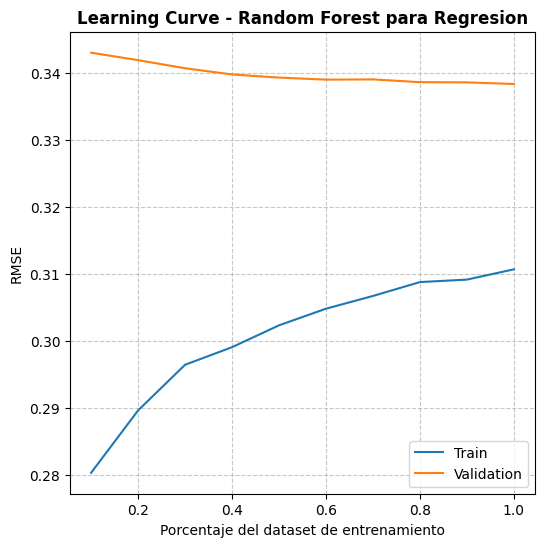

In [52]:
plot_learning_curves_randomforest_regression(X_train_regresion, y_train_regresion, X_val_regresion, y_val_regresion, **mejores_parametros)

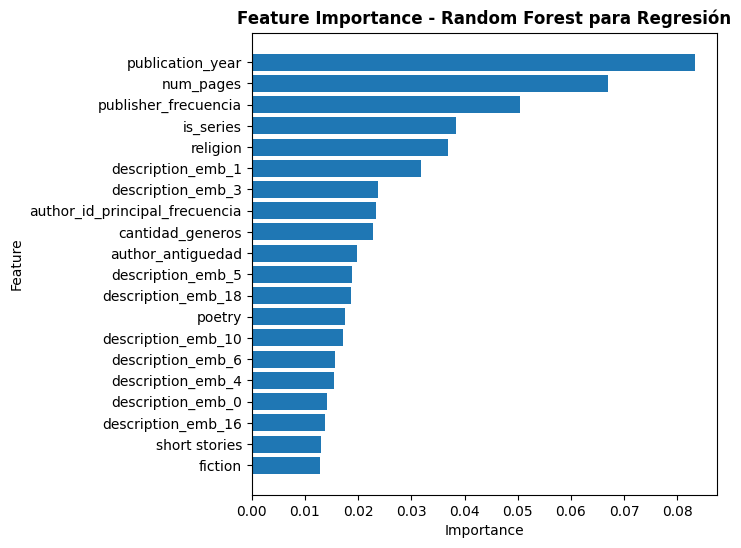

In [53]:
importancias_coef_rf_reg = pd.DataFrame({"feature": columnas_regresion, "importance": modeloRandomForestRegresion.feature_importances_})
importancias_coef_rf_reg = importancias_coef_rf_reg.sort_values("importance", ascending = False)
plot_feature_importance_rf(importancias_coef_rf_reg, "para Regresión")

## Random Forest con features avanzadas - Clasificacion

Uso rebalanceo undersampling + cost re weight, con los pesos y cantidades optimos encontrados en Modelo Base.

### Cost + undersampling

Fitting 3 folds for each of 18 candidates, totalling 54 fits
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=10, min_samples_split=5, n_estimators=300; total time= 1.0min
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=10, min_samples_split=5, n_estimators=300; total time= 1.0min
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=10, min_samples_split=2, n_estimators=300; total time= 1.0min
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=10, min_samples_split=5, n_estimators=300; total time= 1.0min
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=5, min_samples_split=2, n_estimators=300; total time= 1.0min
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=10, min_samples_split=2, n_estimators=300; total time= 1.0min
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=10, min_samples_split=2, n_estimators=300; total time= 1.0min
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=5, min_samples_split=5, n_estimato

,Train,Validation
Accuracy,0.793357,0.783318
Precision,0.642495,0.312284
Recall,0.330215,0.272712
F1,0.361674,0.284056


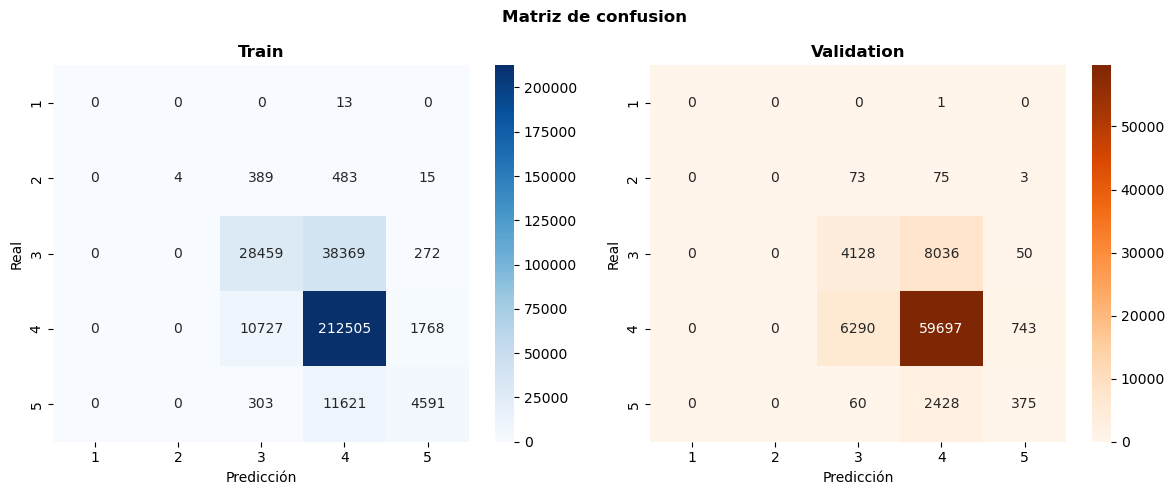

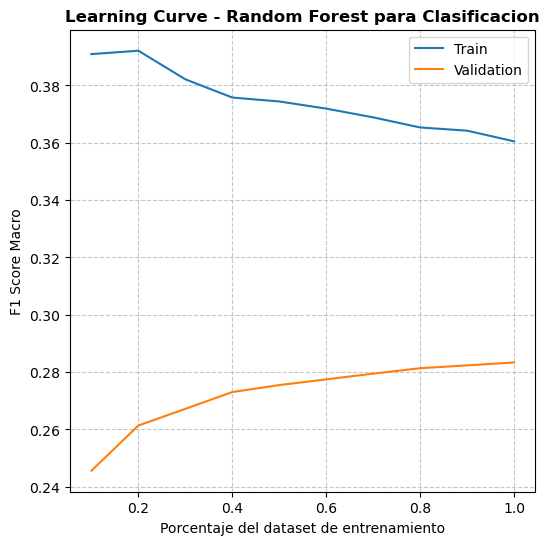

In [ ]:
mejores_parametros = grid_search_rf_clasificacion(pesos_undersampling_cost, X_sub_undersampling, y_sub_clasificacion_undersampling, parametros_grid_search_rf)
tabla_metricas_rf_clasificacion_undersampling_cost, modeloRandomForestClasificacion = evaluar_modelo_rf_clasificacion(mejores_parametros, pesos_undersampling_cost, X_train_undersampling, y_train_undersampling, X_val_clasificacion, y_val_clasificacion)
plot_learning_curves_randomforest_classification(X_train_undersampling, y_train_undersampling, X_val_clasificacion, y_val_clasificacion, pesos=pesos_undersampling_cost, **mejores_parametros)

Analizamos la feature importance:

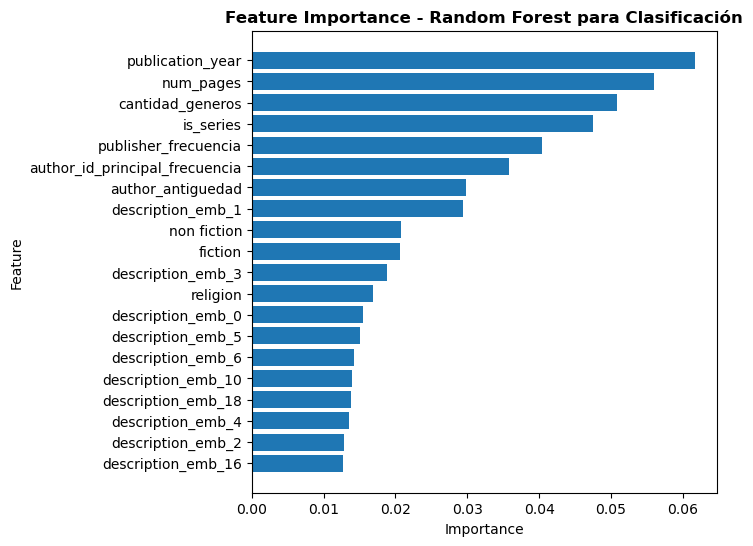

In [20]:
importancias_coef_rf_clasf = pd.DataFrame({"feature": columnas_clasificacion, "importance": modeloRandomForestClasificacion.feature_importances_})
importancias_coef_rf_clasf = importancias_coef_rf_clasf.sort_values("importance", ascending = False)
plot_feature_importance_rf(importancias_coef_rf_clasf, "para Clasificación")

### Cost sin undersampling

Fitting 3 folds for each of 18 candidates, totalling 54 fits
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=5, min_samples_split=5, n_estimators=300; total time= 1.5min
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=5, min_samples_split=2, n_estimators=300; total time= 1.5min
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=10, min_samples_split=5, n_estimators=300; total time= 1.5min
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=5, min_samples_split=5, n_estimators=300; total time= 1.5min
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=10, min_samples_split=2, n_estimators=300; total time= 1.5min
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=5, min_samples_split=2, n_estimators=300; total time= 1.5min
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=10, min_samples_split=5, n_estimators=300; total time= 1.5min
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=10, min_samples_split=2, n_estimators

,Train,Validation
Accuracy,0.833192,0.815652
Precision,0.462588,0.357470
Recall,0.275016,0.233594
F1,0.294726,0.239353


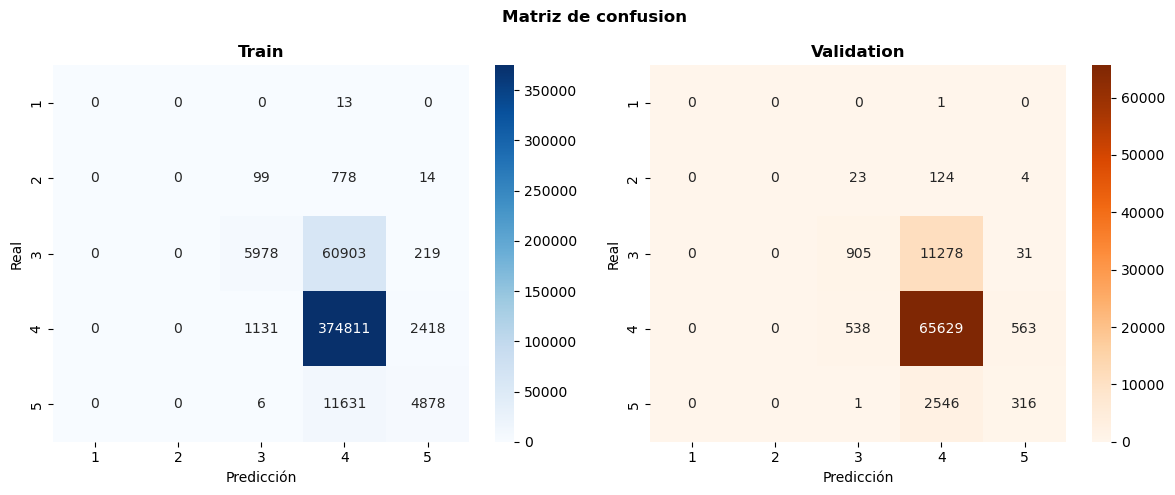

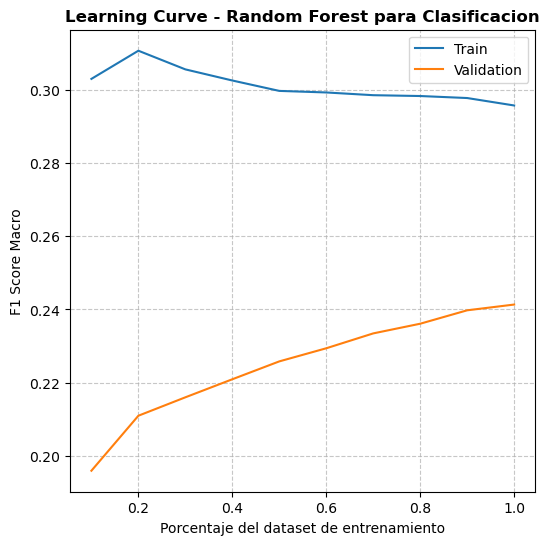

In [ ]:
mejores_parametros = grid_search_rf_clasificacion(pesos_cost, X_sub_clasificacion, y_sub_clasificacion, parametros_grid_search_rf)
tabla_metricas_rf_clasificacion_cost, modeloRandomForestClasificacion = evaluar_modelo_rf_clasificacion(mejores_parametros, pesos_cost, X_train_clasificacion, y_train_clasificacion, X_val_clasificacion, y_val_clasificacion)
plot_learning_curves_randomforest_classification(X_train_clasificacion, y_train_clasificacion, X_val_clasificacion, y_val_clasificacion, pesos=pesos_cost, **mejores_parametros)

Analizamos la feature importance:

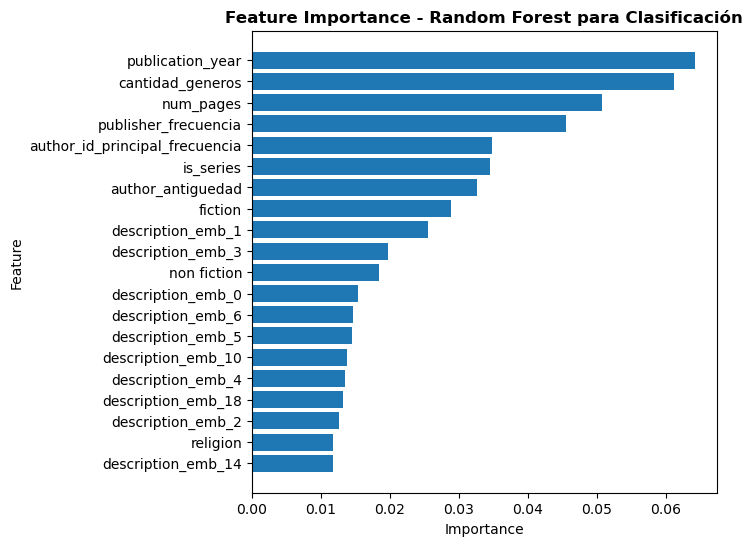

In [22]:
importancias_coef_rf_clasf = pd.DataFrame({"feature": columnas_clasificacion, "importance": modeloRandomForestClasificacion.feature_importances_})
importancias_coef_rf_clasf = importancias_coef_rf_clasf.sort_values("importance", ascending = False)
plot_feature_importance_rf(importancias_coef_rf_clasf, "para Clasificación")

## XGBoost con features avanzadas - Regresion

Empiezo con grid search para buscar los mejores hiperparametros:

In [18]:
XGBoostGridSearchRegresion = XGBRegressor(objective = "reg:squarederror", device = "cuda", tree_method = "hist", random_state = 42)
grid = GridSearchCV(estimator = XGBoostGridSearchRegresion, param_grid = parametros_grid_search_xgb, cv = 3, scoring = "r2", n_jobs = 1, verbose = 1)
grid.fit(X_sub_regresion, y_sub_regresion)
mejores_parametros = grid.best_params_
print(f"Mejores parametros: {mejores_parametros}")
print(f"Mejor R² CV: {grid.best_score_}")

Fitting 3 folds for each of 8 candidates, totalling 24 fits


/home/czava/.local/lib/python3.10/site-packages/xgboost/core.py:751: UserWarning: [22:59:06] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


Mejores parametros: {'colsample_bytree': 0.8, 'learning_rate': 0.05, 'max_depth': 7, 'n_estimators': 300, 'subsample': 0.8}
Mejor R² CV: 0.2626507290314505


In [19]:
#subsample --> en cada arbol solo usa una fraccion de las filas (muestras) --> ayuda a descorrelacionar
#colsample_bytree --> solo usa una fraccion de las columnas (features) --> ayuda a descorrelacionar
modeloXGBoostRegresion = XGBRegressor(**mejores_parametros, objective = "reg:squarederror", device = "cuda", tree_method = "hist", random_state = 42) #MInimiza MSE
modeloXGBoostRegresion.fit(X_train_regresion, y_train_regresion) #XGBoost no requiere obligatoriamnete que se escalen los valores, pero lo hag para poder comprar la feature importance

y_pred_train_modeloXGBoostRegresion = modeloXGBoostRegresion.predict(X_train_regresion)
y_pred_val_modeloXGBoostRegresion = modeloXGBoostRegresion.predict(X_val_regresion)

metricas_train = evaluar_metricas_regresion(y_pred_train_modeloXGBoostRegresion, y_train_regresion)
metricas_val = evaluar_metricas_regresion(y_pred_val_modeloXGBoostRegresion, y_val_regresion)
tabla_metricas_xgboost_regresion = tabla_metricas(metricas_train, metricas_val, ["MSE", "RMSE", "MAE", "R²"])
display(tabla_metricas_xgboost_regresion)

,Train,Validation
MSE,0.094070,0.109727
RMSE,0.306709,0.331251
MAE,0.235023,0.259332
R²,0.334818,0.226402


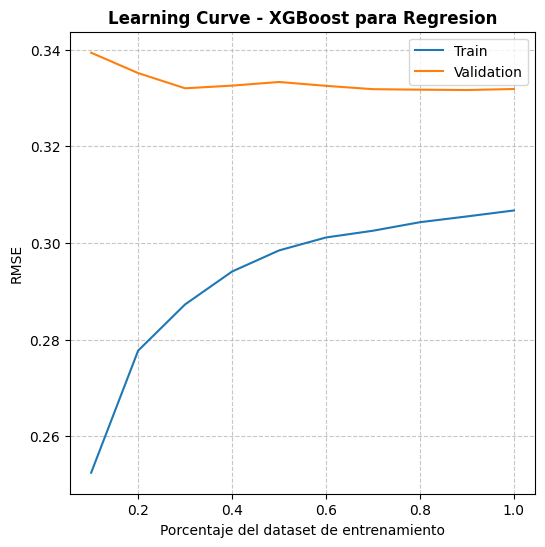

In [20]:
plot_learning_curves_xgboost_regression(X_train_regresion, y_train_regresion, X_val_regresion, y_val_regresion, **mejores_parametros)

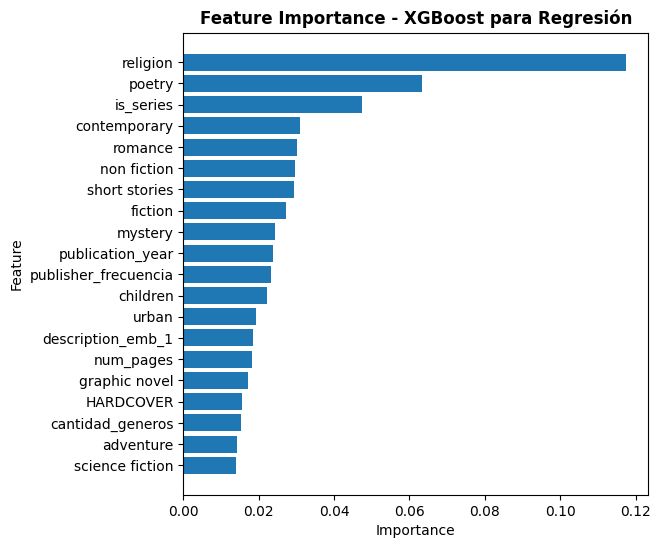

In [21]:
importancias_coef_xgb_reg = pd.DataFrame({"feature": columnas_regresion, "importance": modeloXGBoostRegresion.feature_importances_})
importancias_coef_xgb_reg = importancias_coef_xgb_reg.sort_values("importance", ascending = False)
plot_feature_importance_xgb(importancias_coef_xgb_reg, "para Regresión")

## XGBoost con features avanzadas - Clasificacion

XGBoost solo trabaja con clases empezando desde 0, (aunque nuestras estrellas vayan de 1 a 5). Para poder entrenar con este modelo, transformo temporalmente el target restando 1. Luego, para volver a las clases normales, sumo 1 a la prediccion.

In [22]:
#transformaciones temporales
y_sub_undersampling_temp = y_sub_clasificacion_undersampling - 1
y_sub_temp = y_sub_clasificacion - 1
y_train_undersampling_temp = y_train_undersampling - 1
y_train_temp = y_train_clasificacion - 1

#exactamente los mismos pesos que antes pero con las clases - 1
pesos_undersampling_cost_xgb = {0:8, 1:10, 2:2, 3:1, 4:3}
pesos_cost_xgb = {0:8, 1:2, 2:2, 3:1, 4:5}

### Cost + undersampling

Fitting 3 folds for each of 8 candidates, totalling 24 fits


Mejores parametros: {'colsample_bytree': 0.8, 'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 300, 'subsample': 0.8}
Mejor F1 CV: 0.32494932864915943


,Train,Validation
Accuracy,0.728417,0.692310
Precision,0.722267,0.306420
Recall,0.587232,0.324717
F1,0.617222,0.298584


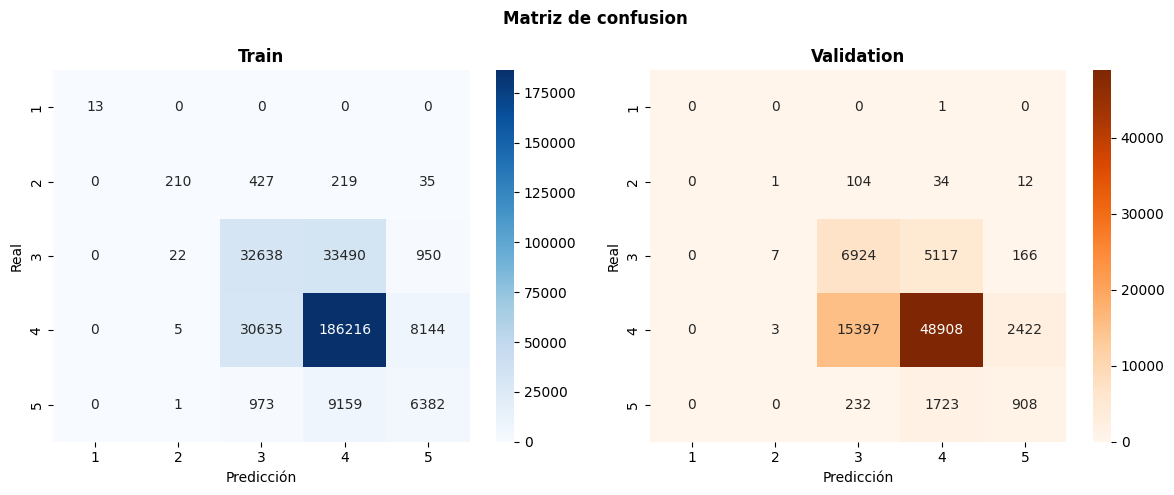

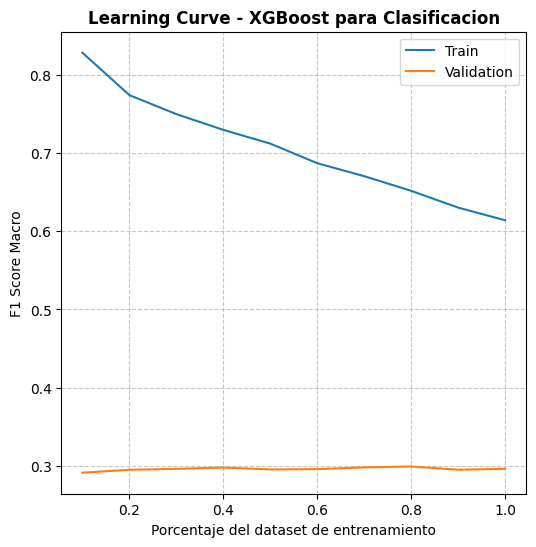

In [ ]:
mejores_parametros = grid_search_xgb_clasificacion(pesos_undersampling_cost_xgb, X_sub_undersampling, y_sub_undersampling_temp, parametros_grid_search_xgb)
tabla_metricas_xgb_clasificacion_undersampling_cost, modeloXGBoostClasificacion = evaluar_modelo_xgb_clasificacion(mejores_parametros, pesos_undersampling_cost_xgb, X_train_undersampling, y_train_undersampling_temp, X_val_clasificacion, y_val_clasificacion)
plot_learning_curves_xgboost_classification(X_train_undersampling, y_train_undersampling, X_val_clasificacion, y_val_clasificacion, pesos=pesos_undersampling_cost_xgb, **mejores_parametros)

Analizamos las feature importance:

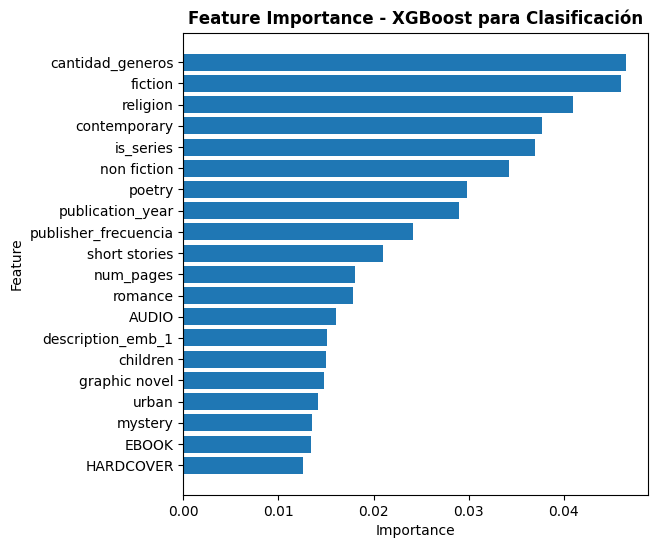

In [25]:
importancias_coef_xgb_clasf = pd.DataFrame({"feature": columnas_clasificacion, "importance": modeloXGBoostClasificacion.feature_importances_})
importancias_coef_xgb_clasf = importancias_coef_xgb_clasf.sort_values("importance", ascending = False)
plot_feature_importance_xgb(importancias_coef_xgb_clasf, "para Clasificación")

### Cost sin undersampling

Fitting 3 folds for each of 8 candidates, totalling 24 fits


Mejores parametros: {'colsample_bytree': 0.8, 'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 300, 'subsample': 0.8}
Mejor F1 CV: 0.29908431700057764


,Train,Validation
Accuracy,0.808088,0.768140
Precision,0.741050,0.302547
Recall,0.572695,0.306827
F1,0.600521,0.304216


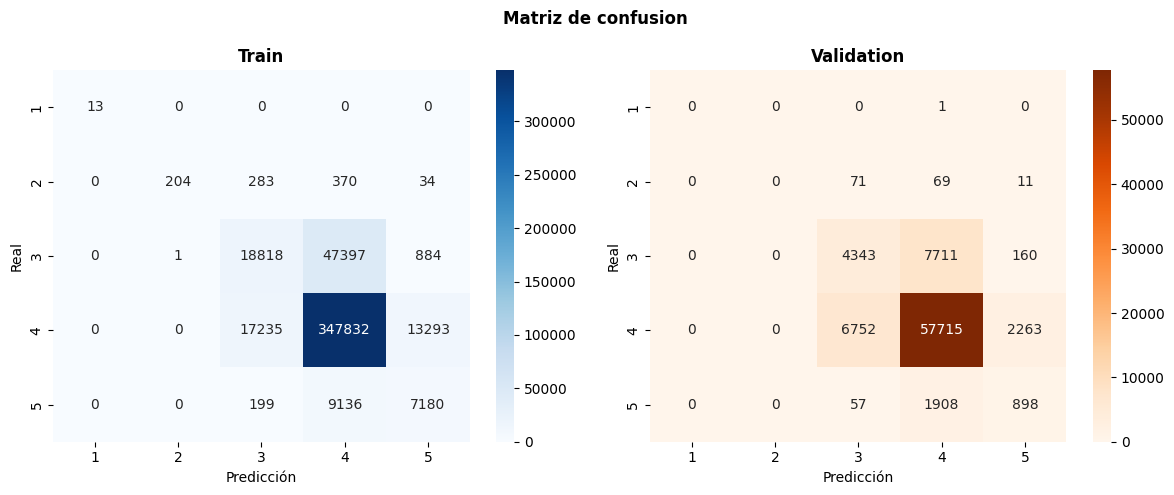

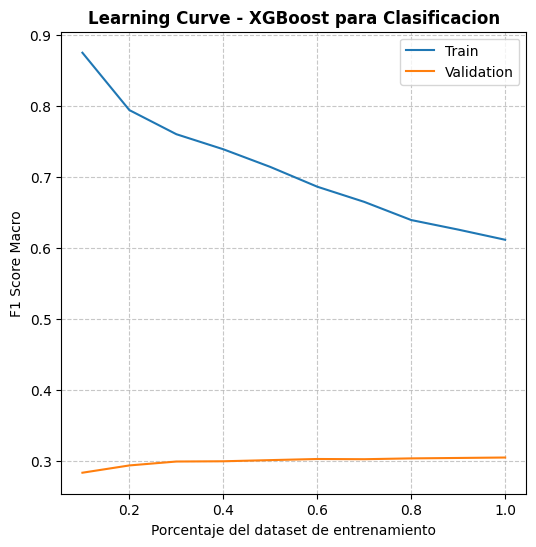

In [ ]:
mejores_parametros = grid_search_xgb_clasificacion(pesos_cost_xgb, X_sub_clasificacion, y_sub_temp, parametros_grid_search_xgb)
tabla_metricas_xgb_clasificacion_cost, modeloXGBoostClasificacion = evaluar_modelo_xgb_clasificacion(mejores_parametros, pesos_cost_xgb, X_train_clasificacion, y_train_temp, X_val_clasificacion, y_val_clasificacion)
plot_learning_curves_xgboost_classification(X_train_clasificacion, y_train_clasificacion, X_val_clasificacion, y_val_clasificacion, pesos = pesos_cost_xgb, **mejores_parametros)

Analizamos las feature importance:

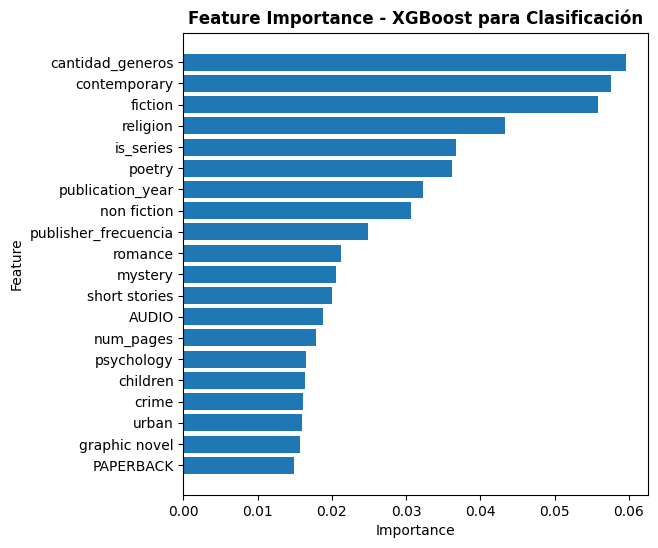

In [27]:
importancias_coef_xgb_clasf = pd.DataFrame({"feature": columnas_clasificacion, "importance": modeloXGBoostClasificacion.feature_importances_})
importancias_coef_xgb_clasf = importancias_coef_xgb_clasf.sort_values("importance", ascending = False)
plot_feature_importance_xgb(importancias_coef_xgb_clasf, "para Clasificación")

## Red neuronal con features avanzadas - Regresion

In [28]:
if torch.cuda.is_available():
  device = "cuda"
else:
  device = "cpu"

Realizamos el Grid Search:

In [29]:
mejor_r2 = -np.inf
mejores_parametros = None

for capas_ocultas in parametros_grid_search_rn["capas_ocultas"]:
    for dropout in parametros_grid_search_rn["dropout"]:
        for lr in parametros_grid_search_rn["lr"]:
            for activacion in parametros_grid_search_rn["funcion_activacion"]:

                modelo = MLP_regresion(input_size = X_sub_regresion.shape[1], hidden_layers = capas_ocultas, activation = activacion, dropout = dropout).to(device)
                r2 = run_grid_search_pytorch_regresion(modelo =modelo, learning_rate = lr, model_name = "MLP Regresion", X_train = X_sub_regresion, y_train = y_sub_regresion, X_val = X_val_regresion, y_val = y_val_regresion, device = device, epochs = 30)
                if r2 > mejor_r2:
                    mejor_r2 = r2
                    mejores_parametros = {"capas_ocultas": capas_ocultas, "dropout": dropout, "lr": lr, "activacion": activacion}

print(f"\nMejores parametros: {mejores_parametros}")

PyTorch: 100%|██████████| 30/30 [00:46<00:00,  1.54s/epoca, epoch=30]



Mejores parametros: {'capas_ocultas': [128, 64], 'dropout': 0.2, 'lr': 0.001, 'activacion': <class 'torch.nn.modules.activation.LeakyReLU'>}


PyTorch:   0%|          | 0/100 [00:00<?, ?epoca/s]

PyTorch: 100%|██████████| 100/100 [09:41<00:00,  5.82s/epoca, epoch=100]


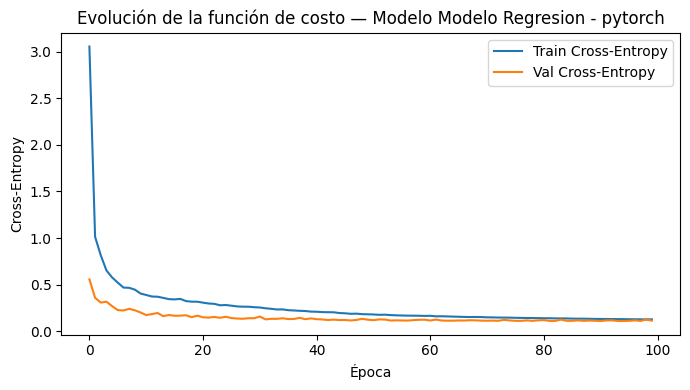

,Train,Validation
MSE,0.110398,0.113846
RMSE,0.332262,0.337411
MAE,0.259011,0.264525
R²,0.219363,0.197359


In [30]:
modelo_regresion = MLP_regresion(input_size = X_train_regresion.shape[1], hidden_layers = mejores_parametros["capas_ocultas"], activation = mejores_parametros["activacion"], dropout = mejores_parametros["dropout"]).to(device)
metricas_train, metricas_val = run_experiment_pytorch_regresion(modelo_regresion, "Modelo Regresion", X_train_regresion, y_train_regresion, X_val_regresion, y_val_regresion, device, learning_rate = mejores_parametros["lr"])
tabla_metricas_mlp_regresion = tabla_metricas(metricas_train, metricas_val, ["MSE", "RMSE", "MAE", "R²"])
display(tabla_metricas_mlp_regresion)

Las redes neuronales con pytorch no tienen un atributo para acceder a la feature importance, a diferencia de XGBoost o Random Forest. Para simular esto, se agarra por separado cada feature y se la mezcla (de esta manera se descorrelaciona la salida del modelo con esta feature). Despues, se predice con esa nueva feature y se evalua la diferencia con el X original. A mayor diferencia mayor impacto tiene la feature. 

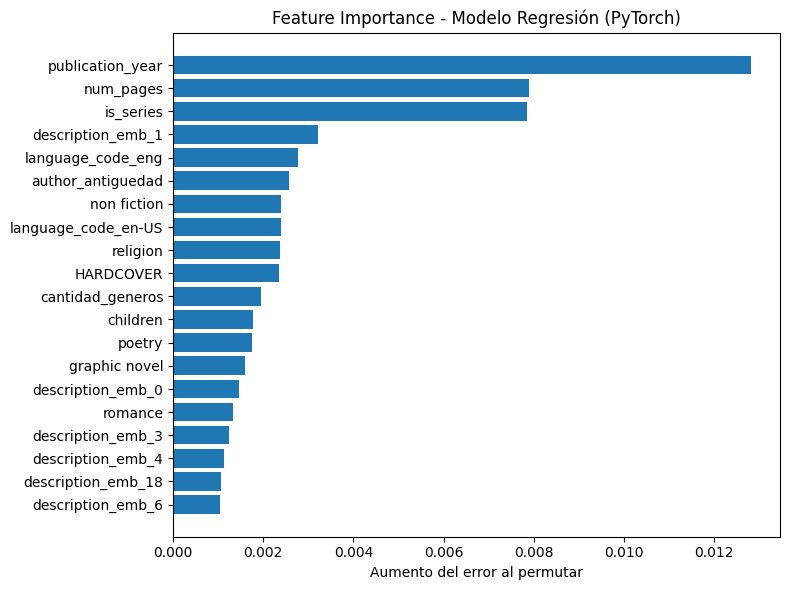

In [31]:
feature_importance_regresion = permutation_importance_pytorch(modelo_regresion, X_val_regresion, y_val_regresion, columnas_regresion, device, metric_fn = mean_squared_error, higher_is_better = False, n_repeats = 10)
plot_feature_importance_pytorch(feature_importance_regresion, top_n = 20, title = "Feature Importance - Modelo Regresión (PyTorch)")

## Red neuronal con features avanzadas - Clasificacion

La red neuronal tambien necesita que las clases empiecen en 0, por lo que adentro de las funciones manejo los conjuntos de y restando 1, y luego sumando 1 a la prediccion. 

### Cost sin undersampling

In [32]:
mejor_f1 = -np.inf
mejores_parametros = None

for capas_ocultas in parametros_grid_search_rn["capas_ocultas"]:
    for dropout in parametros_grid_search_rn["dropout"]:
        for lr in parametros_grid_search_rn["lr"]:
            for activacion in parametros_grid_search_rn["funcion_activacion"]:

                print(f"Probando: {capas_ocultas}, dropout = {dropout}, lr = {lr}, activacion = {activacion.__name__}")
                modelo = MLP_clasificacion(input_size = X_sub_clasificacion.shape[1], hidden_layers = capas_ocultas, n_classes = 5, activation = activacion, dropout = dropout).to(device)
                f1 = run_grid_search_pytorch_clasificacion(modelo = modelo, learning_rate = lr, model_name = "MLP Clasificacion", X_train = X_sub_clasificacion, y_train = y_sub_clasificacion, X_val = X_val_clasificacion, y_val = y_val_clasificacion, device = device, epochs = 30, pesos = pesos_cost)
                if f1 > mejor_f1:
                    mejor_f1 = f1
                    mejores_parametros = {"capas_ocultas": capas_ocultas, "dropout": dropout, "lr": lr, "activacion": activacion}

print(f"\nMejores parametros: {mejores_parametros}")

Probando: [128, 64], dropout = 0.0, lr = 0.001, activacion = ReLU


PyTorch:   0%|          | 0/30 [00:00<?, ?epoca/s]

PyTorch: 100%|██████████| 30/30 [00:45<00:00,  1.52s/epoca, epoch=30]


Probando: [128, 64], dropout = 0.0, lr = 0.001, activacion = LeakyReLU


PyTorch: 100%|██████████| 30/30 [00:48<00:00,  1.61s/epoca, epoch=30]


...

Probando: [256, 128, 64], dropout = 0.2, lr = 0.0001, activacion = ReLU


PyTorch: 100%|██████████| 30/30 [00:45<00:00,  1.50s/epoca, epoch=30]


Probando: [256, 128, 64], dropout = 0.2, lr = 0.0001, activacion = LeakyReLU


PyTorch: 100%|██████████| 30/30 [00:45<00:00,  1.53s/epoca, epoch=30]



Mejores parametros: {'capas_ocultas': [256, 128, 64], 'dropout': 0.2, 'lr': 0.001, 'activacion': <class 'torch.nn.modules.activation.LeakyReLU'>}


PyTorch:   0%|          | 0/100 [00:00<?, ?epoca/s]

PyTorch: 100%|██████████| 100/100 [09:58<00:00,  5.99s/epoca, epoch=100]


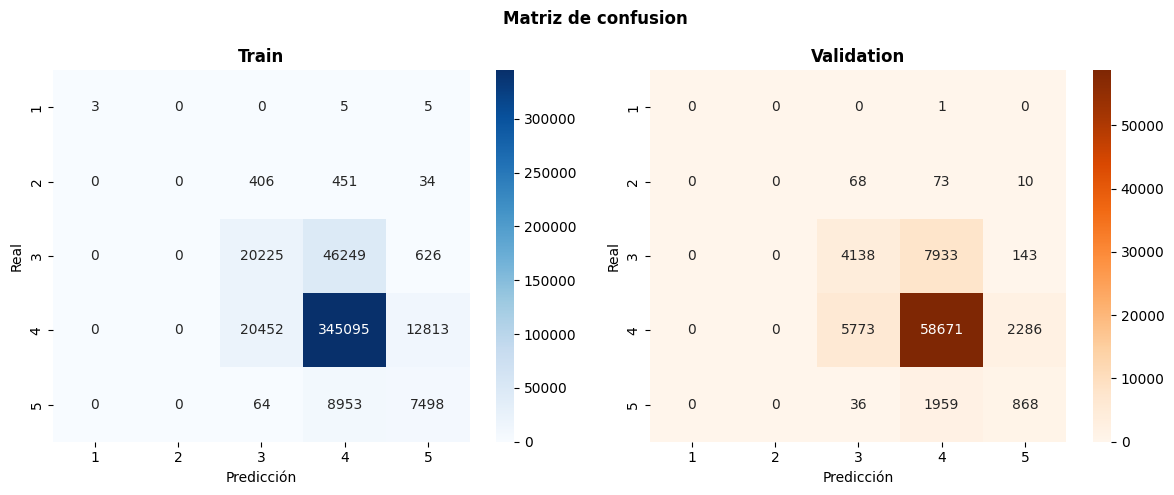

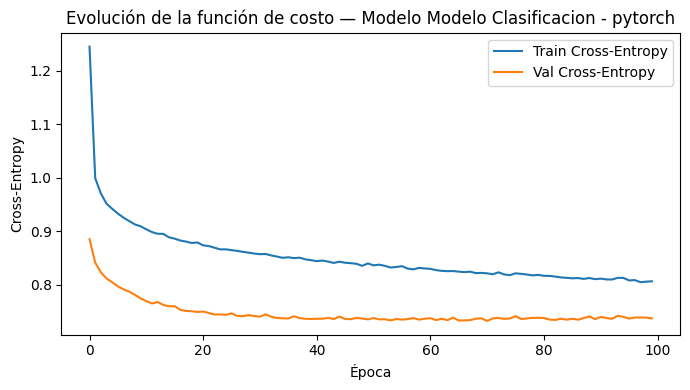

,Train,Validation
Accuracy,0.805439,0.776937
Precision,0.542021,0.306091
Recall,0.379656,0.304240
F1_score,0.406908,0.304102


In [33]:
modelo_clasificacion = MLP_clasificacion(input_size = X_train_clasificacion.shape[1], hidden_layers = mejores_parametros["capas_ocultas"], n_classes = 5, activation = mejores_parametros["activacion"], dropout = mejores_parametros["dropout"]).to(device)
metricas_train, metricas_val = run_experiment_pytorch_clasificacion(modelo_clasificacion, "Modelo Clasificacion", X_train_clasificacion, y_train_clasificacion, X_val_clasificacion, y_val_clasificacion, device, learning_rate = mejores_parametros["lr"], pesos = pesos_cost)
tabla_metricas_mlp_clasificacion = tabla_metricas(metricas_train, metricas_val, ["Accuracy", "Precision", "Recall", "F1_score"])
display(tabla_metricas_mlp_clasificacion)

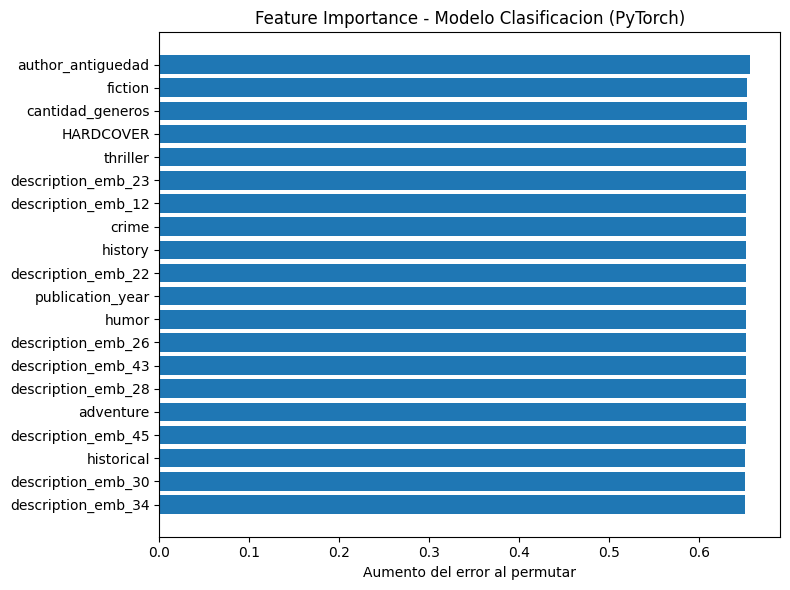

In [34]:
feature_importance_clasificacion = permutation_importance_pytorch(modelo_clasificacion, X_val_clasificacion, y_val_clasificacion, columnas_clasificacion, device, metric_fn = accuracy_score, higher_is_better = True, n_repeats = 10, clasificacion = True)
plot_feature_importance_pytorch(feature_importance_clasificacion, top_n = 20, title = "Feature Importance - Modelo Clasificacion (PyTorch)")

### Cost + undersampling

In [35]:
mejor_f1 = -np.inf
mejores_parametros = None

for capas_ocultas in parametros_grid_search_rn["capas_ocultas"]:
    for dropout in parametros_grid_search_rn["dropout"]:
        for lr in parametros_grid_search_rn["lr"]:
            for activacion in parametros_grid_search_rn["funcion_activacion"]:

                print(f"Probando: {capas_ocultas}, dropout = {dropout}, lr = {lr}, activacion = {activacion.__name__}")
                modelo = MLP_clasificacion(input_size = X_sub_undersampling.shape[1], hidden_layers = capas_ocultas, n_classes = 5, activation = activacion, dropout = dropout).to(device)
                f1 = run_grid_search_pytorch_clasificacion(modelo = modelo, learning_rate = lr, model_name = "MLP Clasificacion", X_train = X_sub_undersampling, y_train = y_sub_clasificacion_undersampling, X_val = X_val_clasificacion, y_val = y_val_clasificacion, device = device, epochs = 30, pesos = pesos_undersampling_cost)
                if f1 > mejor_f1:
                    mejor_f1 = f1
                    mejores_parametros = {"capas_ocultas": capas_ocultas, "dropout": dropout, "lr": lr, "activacion": activacion}

print(f"\nMejores parametros: {mejores_parametros}")

Probando: [128, 64], dropout = 0.0, lr = 0.001, activacion = ReLU


PyTorch:   0%|          | 0/30 [00:00<?, ?epoca/s]

PyTorch: 100%|██████████| 30/30 [00:38<00:00,  1.30s/epoca, epoch=30]


Probando: [128, 64], dropout = 0.0, lr = 0.001, activacion = LeakyReLU


PyTorch: 100%|██████████| 30/30 [00:38<00:00,  1.30s/epoca, epoch=30]


...

Probando: [256, 128, 64], dropout = 0.2, lr = 0.0001, activacion = ReLU


PyTorch: 100%|██████████| 30/30 [00:39<00:00,  1.31s/epoca, epoch=30]


Probando: [256, 128, 64], dropout = 0.2, lr = 0.0001, activacion = LeakyReLU


PyTorch: 100%|██████████| 30/30 [00:38<00:00,  1.28s/epoca, epoch=30]



Mejores parametros: {'capas_ocultas': [256, 128, 64], 'dropout': 0.2, 'lr': 0.001, 'activacion': <class 'torch.nn.modules.activation.ReLU'>}


PyTorch:   0%|          | 0/100 [00:00<?, ?epoca/s]

PyTorch: 100%|██████████| 100/100 [05:43<00:00,  3.43s/epoca, epoch=100]


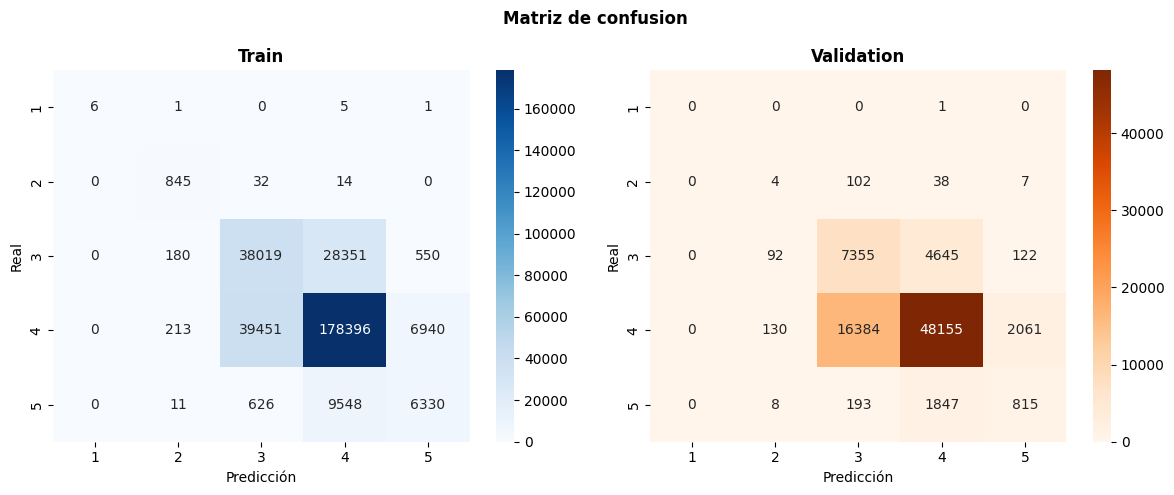

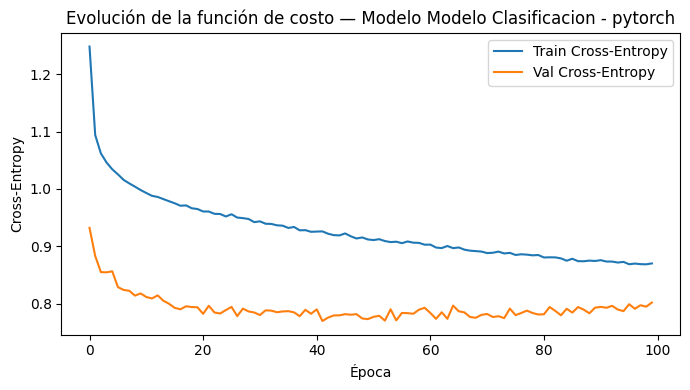

,Train,Validation
Accuracy,0.722398,0.687283
Precision,0.689066,0.294981
Recall,0.630534,0.326995
F1_score,0.634062,0.299519


In [36]:
modelo_clasificacion = MLP_clasificacion(input_size = X_train_undersampling.shape[1], hidden_layers = mejores_parametros["capas_ocultas"], n_classes = 5, activation = mejores_parametros["activacion"], dropout = mejores_parametros["dropout"]).to(device)
metricas_train, metricas_val = run_experiment_pytorch_clasificacion(modelo_clasificacion, "Modelo Clasificacion", X_train_undersampling, y_train_undersampling, X_val_clasificacion, y_val_clasificacion, device, learning_rate = mejores_parametros["lr"], pesos = pesos_undersampling_cost)
tabla_metricas_mlp_clasificacion_undersampling = tabla_metricas(metricas_train, metricas_val, ["Accuracy", "Precision", "Recall", "F1_score"])
display(tabla_metricas_mlp_clasificacion_undersampling)

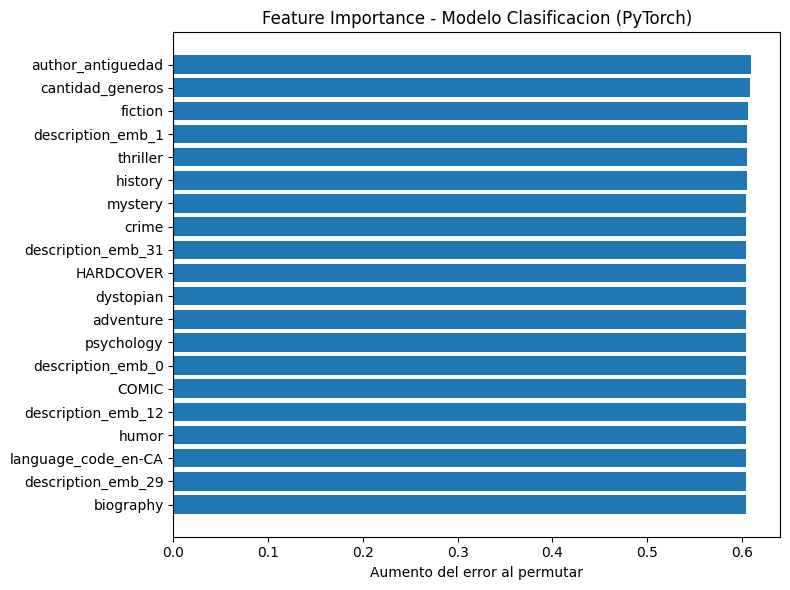

In [37]:
feature_importance_clasificacion = permutation_importance_pytorch(modelo_clasificacion, X_val_clasificacion, y_val_clasificacion, columnas_clasificacion, device, metric_fn = accuracy_score, higher_is_better = True, n_repeats = 10, clasificacion = True)
plot_feature_importance_pytorch(feature_importance_clasificacion, top_n=20, title="Feature Importance - Modelo Clasificacion (PyTorch)")

## Comparando modelos

In [38]:
tabla_metricas_rf_regresion = pd.DataFrame({"Train": [0.082720, 0.287611, 0.219830, 0.415076], "Validation": [0.112964, 0.336101, 0.260872, 0.203582]}, index=["MSE", "RMSE", "MAE", "R²"])
tabla_metricas_rf_clasificacion_undersampling_cost = pd.DataFrame({"Train": [0.820434, 0.477595, 0.391444, 0.421684], "Validation": [0.764358, 0.308524, 0.272472, 0.276963]}, index=["Accuracy", "Precision", "Recall", "F1"])
tabla_metricas_rf_clasificacion_cost = pd.DataFrame({"Train": [0.853048, 0.491635, 0.336606, 0.368837], "Validation": [0.813382, 0.336334, 0.235527, 0.244745]}, index=["Accuracy", "Precision", "Recall", "F1"])

In [ ]:
print("Comparacion de tablas de metricas:")

print("\nRANDOM FOREST:")
print("Regresion:")
display(tabla_metricas_rf_regresion)
print("\nClasificacion undersampling + cost:")
display(tabla_metricas_rf_clasificacion_undersampling_cost)
print("\nClasificacion cost:")
display(tabla_metricas_rf_clasificacion_cost)

print("\nXGBOOST:")
print("Regresion:")
display(tabla_metricas_xgboost_regresion)
print("\nClasificacion undersampling + cost:")
display(tabla_metricas_xgb_clasificacion_undersampling_cost)
print("\nClasificacion cost:")
display(tabla_metricas_xgb_clasificacion_cost)

print("\nRED NEURONAL:")
print("Regresion:")
display(tabla_metricas_mlp_regresion)
print("\nClasificacion undersampling + cost:")
display(tabla_metricas_mlp_clasificacion)
print("\nClasificacion cost:")
display(tabla_metricas_mlp_clasificacion_undersampling)

Comparacion de tablas de metricas:

RANDOM FOREST:
Regresion:


,Train,Validation
MSE,0.096386,0.114484
RMSE,0.310460,0.338354
MAE,0.239408,0.262543
R²,0.318446,0.192866



Clasificacion undersampling + cost:


,Train,Validation
Accuracy,0.793357,0.783318
Precision,0.642495,0.312284
Recall,0.330215,0.272712
F1,0.361674,0.284056



Clasificacion cost:


...

,Train,Validation
MSE,0.110398,0.113846
RMSE,0.332262,0.337411
MAE,0.259011,0.264525
R²,0.219363,0.197359



Clasificacion undersampling + cost:


,Train,Validation
Accuracy,0.805439,0.776937
Precision,0.542021,0.306091
Recall,0.379656,0.304240
F1,0.406908,0.304102



Clasificacion cost:


,Train,Validation
Accuracy,0.722398,0.687283
Precision,0.689066,0.294981
Recall,0.630534,0.326995
F1,0.634062,0.299519


# Comparación de modelos y conclusiones

A partir de estos resultados, podemos decir que: 

## Regresion
Para el problema de regresion, podemos descartar el modelo MLP, ya que presenta los mayores errores (MSE, RMSE y MAE) y un valor de R^2 menor respecto de los otros dos modelos. En cuanto a Random Forest y XGBoost, ambos tuvieron un desempeño considerablemente mejor. Sin embargo, XGBoost logro los mejores resultados en todas las metricas de validacion, alcanzando el menor error y el mayor R^2. Ademas, al comparar las metricas de entrenamiento y validacion, ambos modelos presentan un leve grado de overfitting, aunque la diferencia es ligeramente menor en XGBoost. Por estos motivos, elegimos a XGBoost como el mejor modelo para regresión en esta etapa. 

## Clasificacion
Por el otro lado, para el problema de clasificacion adoptamos dos enfoques distintos para tratar el desbalance de clases: aplicar Cost Sensitive Learning o combinar esta tecnica con undersampling. Al comparar el F1-Score de validacion, observamos que Random Forest y la red neuronal obtienen su mejor desempeño utilizando Cost + undersampling, mientras que XGBoost alcanza sus mejores resultados empleando únicamente Cost Sensitive Learning.

Luego, al comparar el mejor resultado obtenido por cada modelo, observamos que Random Forest logra el mayor accuracy, aunque presenta el menor recall y F1-Score. Por otro lado, XGBoost y la MLP obtienen valores de F1-Score practicamente identicos, con una diferencia despreciable entre ambos, y un desempeño general muy similar. Y como nuestro criterio principal de seleccion es maximizar el F1-Macro, elegimos la MLP con Cost + undersampling como el mejor modelo para clasificación en esta etapa.